# Exact monogamy of steering and remote Wigner negativity for multimode Gaussian nodes

**Numerical results and figures**

Sudip Chakrabarty, S. N. Bose National Centre for Basic Sciences, Kolkata, India

This notebook reproduces every numerical value quoted in the paper and all seven figures, in the order in which they appear in the paper. Every cell has been executed, and its output is stored in the notebook, so all numbers and figures can be read directly on GitHub without running anything.

**Requirements.** Python 3 with `numpy`, `scipy`, `matplotlib`, `mpmath` and, for the semidefinite programs of Sec. 7.4, `cvxpy` with the SCS solver.

```
pip install numpy scipy matplotlib mpmath cvxpy scs
```

**Run modes.** The stored outputs were produced with `QUICK = False`, which uses the grids and numbers of random starts of the paper and takes about forty minutes on a standard computer, mostly in the semidefinite programs and the $I_{3322}$ scan. Setting `QUICK = True` uses coarser grids and fewer starts and runs in about twenty minutes. All analytic checks are identical in both modes. Figures are saved as PDF files in the folder `figures/`.

**Conventions.** Quadratures $\hat x=\hat a+\hat a^\dagger$ and $\hat p=-i(\hat a-\hat a^\dagger)$, vacuum covariance matrix $\mathbb 1$, symplectic form $\Omega=\bigoplus_j J$ with $J=\begin{pmatrix}0&1\\-1&0\end{pmatrix}$. Theorem, proposition, equation, table and section numbers refer to the paper.

**Contents**

0. Setup, Gaussian toolbox and plotting style
1. Figure 1 (Sec. 1)
2. The share of a neighbor (Sec. 3): Propositions 1 and 3, Table 2, Figure 2, Proposition 4
3. The share bound (Sec. 4): Theorem 1, Proposition 5, Lemma 4
4. Exact count for steering (Sec. 5): Theorem 2 and Proposition 6
5. Remote Wigner negativity (Sec. 6): Theorem 5, rates and imperfections, Figure 3
6. Arbitrary measurements (Sec. 7): Theorem 7 and Figure 4, three and four settings, certificates (Table 5), $I_{3322}$, Figure 5
7. Teleportation and entanglement (Sec. 8): Theorem 8, Proposition 9, Figure 6, Figure 7


## 0. Setup

In [1]:
QUICK = False         # False reproduces the data of the paper (about forty minutes), True gives a quick run
import os, json, itertools, time
import numpy as np
from math import factorial, sqrt
from scipy.linalg import expm
from scipy.optimize import minimize, minimize_scalar
from scipy.special import eval_laguerre, comb
import warnings
# silence two harmless warnings: SCS accuracy notices for programs whose value is zero at the threshold,
# and overflow in random fidelity searches that start far from the optimum
warnings.filterwarnings("ignore", message="Solution may be inaccurate")
warnings.filterwarnings("ignore", category=RuntimeWarning)
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, RegularPolygon
%matplotlib inline
OUT = 'figures/'; os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(1)
T0 = time.time()

### Gaussian toolbox and the share $\zeta_j$
The share is $\zeta_j=(1+\kappa_j-\mu_j)/2$ (Definition 1, Eq. (14) of the paper), read off from $Q_j=V_{Y_j}-V_{Y_jA}(V_A+i\Omega_A)^{-1}V_{AY_j}=M_j-i\kappa_jJ$ with $\mu_j=\sqrt{\det M_j}$. Random states are built in the purified picture of Sec. 2.4, with $k$ two-mode squeezed vacua whose partner modes enter a random symplectic transformation together with vacuum modes.

In [2]:
J = np.array([[0., 1.], [-1., 0.]]); Z = np.diag([1., -1.]); I2 = np.eye(2)
def Om(n): return np.kron(np.eye(n), J)

def rand_symp(n, scale=0.6):
    S = np.eye(2*n)
    for _ in range(2):
        H = rng.normal(size=(2*n, 2*n))*scale; H = (H + H.T)/2
        S = S @ expm(Om(n) @ H)
    return S

def tmsv(k, r):
    v, s = np.cosh(2*r), np.sinh(2*r); V = np.zeros((4*k, 4*k))
    for l in range(k):
        a, b = 2*l, 2*k + 2*l
        V[a:a+2, a:a+2] = v[l]*I2; V[b:b+2, b:b+2] = v[l]*I2
        V[a:a+2, b:b+2] = s[l]*Z; V[b:b+2, a:a+2] = s[l]*Z
    return V

def state(k, Sch, r):
    # node A (k modes) + partners B (k) + vacua; Sch acts on partners + vacua
    n = Sch.shape[0]//2; V0 = np.eye(2*k + 2*n); V0[:4*k, :4*k] = tmsv(k, r)
    L = np.eye(2*k + 2*n); L[2*k:, 2*k:] = Sch
    return L @ V0 @ L.T

def blocks(V, k, j):
    idx = list(range(2*k)) + [2*k + 2*j, 2*k + 2*j + 1]
    W = V[np.ix_(idx, idx)]
    return W[:2*k, :2*k], W[:2*k, 2*k:], W[2*k:, 2*k:]

def share(VA, VAY, VY, k):
    Q = VY - VAY.T @ np.linalg.inv(VA + 1j*Om(k)) @ VAY
    M = Q.real; kap = -Q.imag[0, 1]; mu = np.sqrt(max(np.linalg.det(M), 0))
    return (1 + kap - mu)/2, kap, mu

def ppt_entangled(VA, VAY, VY, k):
    W = np.block([[VA, VAY], [VAY.T, VY]])
    P = W + 1j*np.block([[Om(k), np.zeros((2*k, 2))], [np.zeros((2, 2*k)), -J]])
    return np.linalg.eigvalsh(P).min() < -1e-10

def sp_from(p, n):
    H = np.zeros((2*n, 2*n)); iu = np.triu_indices(2*n); H[iu] = p; H = (H + H.T)/2
    return expm(Om(n) @ H)

### Plotting style

In [3]:
plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['STIXGeneral'], 'mathtext.fontset': 'stix',
    'font.size': 10.5, 'axes.labelsize': 11, 'legend.fontsize': 9.5,
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.linewidth': 1.0,
    'lines.linewidth': 2.0, 'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.top': True, 'ytick.right': True, 'xtick.major.size': 4, 'ytick.major.size': 4,
    'legend.frameon': False, 'hatch.linewidth': 0.8})
RED, BLUE, ORANGE, GREEN, PURPLE, TEAL = '#d7191c', '#1565c0', '#f28e00', '#1a8a3a', '#7b2cbf', '#00838f'
GRAY, DARK, MID = '#e3e3e3', '#222222', '#666666'
COLS = [RED, BLUE, GREEN, ORANGE, PURPLE]


def grid(ax):
    ax.grid(True, color='#d0d0d0', lw=0.6, zorder=0)
    ax.set_axisbelow(True)


def plabel(ax, t, x, y, ha='left'):
    ax.text(x, y, t, transform=ax.transAxes, fontsize=12, fontweight='bold', va='top', ha=ha)


def toplegend(ax, ncol, **kw):
    opts = dict(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=ncol, columnspacing=1.0,
                handlelength=1.8, handletextpad=0.4, borderaxespad=0.0)
    opts.update(kw)
    ax.legend(**opts)


LEG = dict(fontsize=9, handlelength=2.2, borderaxespad=0.6, labelspacing=0.35)
OPEN = dict(mfc='none', mew=1.3)   # hollow markers, so overlapping points and lines stay visible

## 1. Figure 1: setting and conditions on the share (Sec. 1)

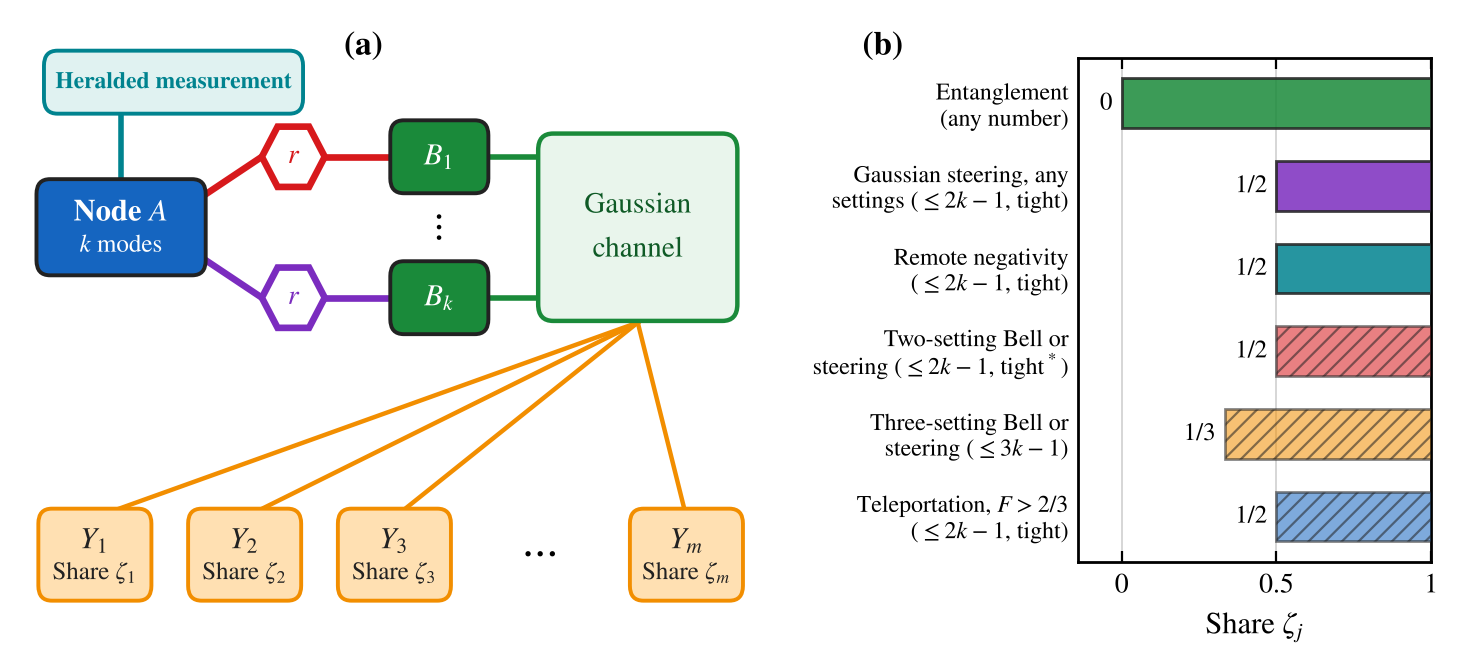

In [4]:
# ============================ Figure 1 ============================
fig = plt.figure(figsize=(7.2, 3.15))
ax = fig.add_axes([0.0, 0.0, 0.52, 1.0]); ax.set_xlim(0, 10); ax.set_ylim(0, 7.6); ax.axis('off')


def box(x, y, w, h, col, t1, t2=None, tc='white', ec=DARK, fs=11):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.08,rounding_size=0.18',
                                fc=col, ec=ec, lw=1.4, zorder=4))
    if t2:
        ax.text(x, y + 0.17, t1, ha='center', va='center', color=tc, fontsize=fs, fontweight='bold', zorder=5)
        ax.text(x, y - 0.23, t2, ha='center', va='center', color=tc, fontsize=9, zorder=5)
    else:
        ax.text(x, y, t1, ha='center', va='center', color=tc, fontsize=fs, fontweight='bold', zorder=5)


def hexa(x, y, col, t):
    ax.add_patch(RegularPolygon((x, y), 6, radius=0.42, orientation=np.pi / 6, fc='white', ec=col, lw=2.4, zorder=4))
    ax.text(x, y, t, ha='center', va='center', color=col, fontsize=10, zorder=5)


box(1.35, 5.1, 2.1, 1.0, BLUE, 'Node $A$', '$k$ modes')
ax.plot([1.35, 1.35], [5.6, 6.5], color=TEAL, lw=2.0, zorder=1)
box(2.05, 6.85, 3.3, 0.6, '#e0f2f1', 'Heralded measurement', tc=TEAL, ec=TEAL, fs=8.5)
for i, (y, col) in enumerate([(5.95, RED), (4.25, PURPLE)]):
    hexa(3.65, y, col, '$r$')
    ax.plot([2.4, 3.23], [5.1 + (0.35 if i == 0 else -0.35), y], color=col, lw=2.4, zorder=2)
    ax.plot([4.07, 5.0], [y, y], color=col, lw=2.4, zorder=2)
    box(5.6, y, 1.15, 0.72, GREEN, '$B_1$' if i == 0 else '$B_k$')
ax.text(5.6, 5.1, r'$\vdots$', ha='center', va='center', fontsize=13)
ax.add_patch(FancyBboxPatch((7.0, 4.05), 2.5, 2.1, boxstyle='round,pad=0.08,rounding_size=0.2',
                            fc='#e9f5ec', ec=GREEN, lw=1.6, zorder=3))
ax.text(8.25, 5.1, 'Gaussian\nchannel', ha='center', va='center', fontsize=10.5, color='#0f5a26', zorder=5)
for y in [5.95, 4.25]:
    ax.plot([6.18, 7.0], [y, y], color=GREEN, lw=2, zorder=2)
xs = [1.0, 3.0, 5.0, 8.9]; labs = ['1', '2', '3', 'm']
for x, l in zip(xs, labs):
    ax.plot([8.25, x], [3.95, 1.6], color=ORANGE, lw=1.6, zorder=1)
    box(x, 1.15, 1.35, 0.95, '#ffe0b2', '$Y_%s$' % l, r'Share $\zeta_%s$' % l, tc=DARK, ec=ORANGE)
ax.text(6.95, 1.15, r'$\cdots$', ha='center', va='center', fontsize=15)

bx = fig.add_axes([0.735, 0.14, 0.245, 0.80])
rows = [('Entanglement\n(any number)', 0, GREEN, False),
        ('Gaussian steering, any\nsettings ' + r'($\leq 2k-1$, tight)', 1 / 2, PURPLE, False),
        ('Remote negativity\n' + r'($\leq 2k-1$, tight)', 1 / 2, TEAL, False),
        ('Two-setting Bell or\nsteering ' + r'($\leq 2k-1$, tight$^*$)', 1 / 2, RED, True),
        ('Three-setting Bell or\nsteering ' + r'($\leq 3k-1$)', 1 / 3, ORANGE, True),
        ('Teleportation, $F>2/3$\n' + r'($\leq 2k-1$, tight)', 1 / 2, BLUE, True)]
n = len(rows)
for i, (lab, th, col, h) in enumerate(rows):
    y = n - 1 - i
    bx.barh(y, 1 - th, left=th, height=0.6, color=col, alpha=0.85 if not h else 0.55, edgecolor=DARK, lw=1.0,
            hatch='////' if h else None, zorder=3)
    bx.text(th - 0.03, y, {0: '0', 1 / 3: '1/3', 1 / 2: '1/2'}[th], ha='right', va='center', fontsize=9)
bx.set_yticks([n - 1 - i for i in range(n)]); bx.set_yticklabels([r[0] for r in rows], fontsize=8.6, linespacing=1.1)
bx.set_xlim(-0.14, 1.0); bx.set_ylim(-0.55, n - 0.45); bx.set_xticks([0, 0.5, 1]); bx.set_xticklabels(['0', '0.5', '1'])
bx.set_xlabel(r'Share $\zeta_j$'); bx.tick_params(axis='y', length=0, right=False)
bx.grid(True, axis='x', color='#d0d0d0', lw=0.6, zorder=0); bx.set_axisbelow(True)
fig.text(0.225, 0.985, '(a)', fontsize=12, fontweight='bold', va='top')
fig.text(0.585, 0.985, '(b)', fontsize=12, fontweight='bold', va='top')
fig.savefig(OUT + 'fig1.pdf'); plt.show()

## 2. The share of a neighbor (Sec. 3)

**Proposition 1 (monotonicity).** Pure loss of transmission $\lambda$ maps $\zeta_j$ to at most $\lambda\zeta_j$, a quantum-limited amplifier of gain $G$ maps it to at most $1-G(1-\zeta_j)$, and $\zeta_j^+$ does not increase under one-mode channels of the neighbor or Gaussian channels of the node. The printed numbers are the largest violations found over random states. Nonpositive values mean no violation.

In [5]:
def zeta_full(V, k): return share(V[:2*k, :2*k], V[:2*k, 2*k:], V[2*k:, 2*k:], k)[0]
worst = {'loss': -9, 'amp': -9, 'channel': -9, 'node': -9}
for t in range(400):
    k = int(rng.integers(1, 3)); n = k + int(rng.integers(1, 3))
    V = state(k, rand_symp(n), rng.uniform(0.2, 1.3, size=k))
    idx = list(range(2*k)) + [2*k, 2*k+1]; W = V[np.ix_(idx, idx)]; z = zeta_full(W, k)
    def recv(X, N):
        L = np.eye(2*k+2); L[2*k:, 2*k:] = X; W2 = L @ W @ L.T; W2[2*k:, 2*k:] += N; return zeta_full(W2, k)
    lam = rng.uniform(0.05, 1); worst['loss'] = max(worst['loss'], recv(np.sqrt(lam)*I2, (1-lam)*I2) - lam*z)
    G = rng.uniform(1, 4); worst['amp'] = max(worst['amp'], recv(np.sqrt(G)*I2, (G-1)*I2) - (1 - G*(1-z)))
    X = rng.normal(size=(2, 2)); A = rng.normal(size=(2, 2)); N = abs(1 - np.linalg.det(X))*I2 + 0.3*A @ A.T
    worst['channel'] = max(worst['channel'], max(recv(X, N), 0) - max(z, 0))
    if k > 1:   # node: symplectic on node + thermal ancilla, then discard one mode
        nth = rng.uniform(0, 2); S = rand_symp(k+1); big = np.zeros((2*k+4, 2*k+4))
        big[:2*k, :2*k] = W[:2*k, :2*k]; big[:2*k, 2*k+2:] = W[:2*k, 2*k:]; big[2*k+2:, :2*k] = W[2*k:, :2*k]
        big[2*k+2:, 2*k+2:] = W[2*k:, 2*k:]; big[2*k:2*k+2, 2*k:2*k+2] = (2*nth+1)*I2
        L = np.eye(2*k+4); L[:2*k+2, :2*k+2] = S; B = L @ big @ L.T
        keep = list(range(2*(k-1))) + [2*k+2, 2*k+3]
        worst['node'] = max(worst['node'], max(zeta_full(B[np.ix_(keep, keep)], k-1), 0) - max(z, 0))
print({a: '%.1e' % b for a, b in worst.items()})

{'loss': '-1.0e-04', 'amp': '-5.5e-04', 'channel': '0.0e+00', 'node': '0.0e+00'}


**Proposition 3 (mode-operator form).** $\zeta_j=\sup\{\sum_{c\leq k}|\alpha_c|^2-\sum_c|\beta_c|^2\}$ over all local Gaussian unitaries of the neighbor. The printed number is the largest deviation between the closed form and the numerical supremum.

In [6]:
def bog_sup(k, Sch, starts=20):
    n = Sch.shape[0]//2; R = Sch[0:2, :]; e = np.array([1, -1j])/np.sqrt(2)
    def val(p):
        row = np.array([1, 1j]) @ sp_from(p, 1) @ R/np.sqrt(2)
        al = [row[2*c:2*c+2] @ e for c in range(n)]; be = [row[2*c:2*c+2] @ e.conj() for c in range(n)]
        return sum(abs(a)**2 for a in al[:k]) - sum(abs(b)**2 for b in be)
    return max(-minimize(lambda p: -val(p), rng.normal(size=3)*0.5).fun for _ in range(starts))
dev = 0
for t in range(10):
    k = int(rng.integers(1, 3)); n = k + int(rng.integers(1, 3)); Sch = rand_symp(n)
    V = state(k, Sch, rng.uniform(0.3, 1.2, size=k)); z = share(*blocks(V, k, 0), k)[0]
    dev = max(dev, abs(z - bog_sup(k, Sch)))
print('max |zeta - sup over mode operators| =', dev)

max |zeta - sup over mode operators| = 4.929390229335695e-14


### Table 2: shares of simple channels (Sec. 3.3)
One partner mode of a two-mode squeezed vacuum is sent through a single-mode Gaussian channel $V_Y=XV_BX^T+N$. The column `zeta` is computed numerically and the column `table` is the closed form of Table 2. The shares do not depend on the squeezing.

In [7]:
def share_channel(X, N, v=3.0):
    s = np.sqrt(v*v - 1)
    return share(v*I2, s*Z @ X.T, X @ (v*I2) @ X.T + N, 1)
eta, Nth, G, nadd = 0.7, 0.4, 2.5, 0.6
rows = [('Pure loss', np.sqrt(eta)*I2, (1-eta)*I2, eta),
        ('Thermal loss', np.sqrt(eta)*I2, (1-eta)*(2*Nth+1)*I2, eta-(1-eta)*Nth),
        ('Amplifier', np.sqrt(G)*I2, (G-1)*I2, 1.0),
        ('Amplifier, split', np.sqrt(G/2)*I2, (G/2)*I2, 0.5),
        ('Additive noise', I2, nadd*I2, 1-nadd/2),
        ('Conjugate output', np.sqrt(G-1)*Z, G*I2, 1-G)]
print(f"{'channel':18s} {'kappa':>8s} {'mu':>8s} {'zeta':>8s} {'table':>8s}")
for name, X, N, pred in rows:
    for v in (1.5, 3.0, 10.0):   # independence of the squeezing
        z, kap, mu = share_channel(X, N, v); assert abs(z - pred) < 1e-9
    print(f"{name:18s} {kap:8.4f} {mu:8.4f} {z:8.4f} {pred:8.4f}")

channel               kappa       mu     zeta    table
Pure loss            0.7000   0.3000   0.7000   0.7000
Thermal loss         0.7000   0.5400   0.5800   0.5800
Amplifier            2.5000   1.5000   1.0000   1.0000
Amplifier, split     1.2500   1.2500   0.5000   0.5000
Additive noise       1.0000   0.6000   0.7000   0.7000
Conjugate output    -1.5000   2.5000  -1.5000  -1.5000


### Figure 2: shares of simple channels

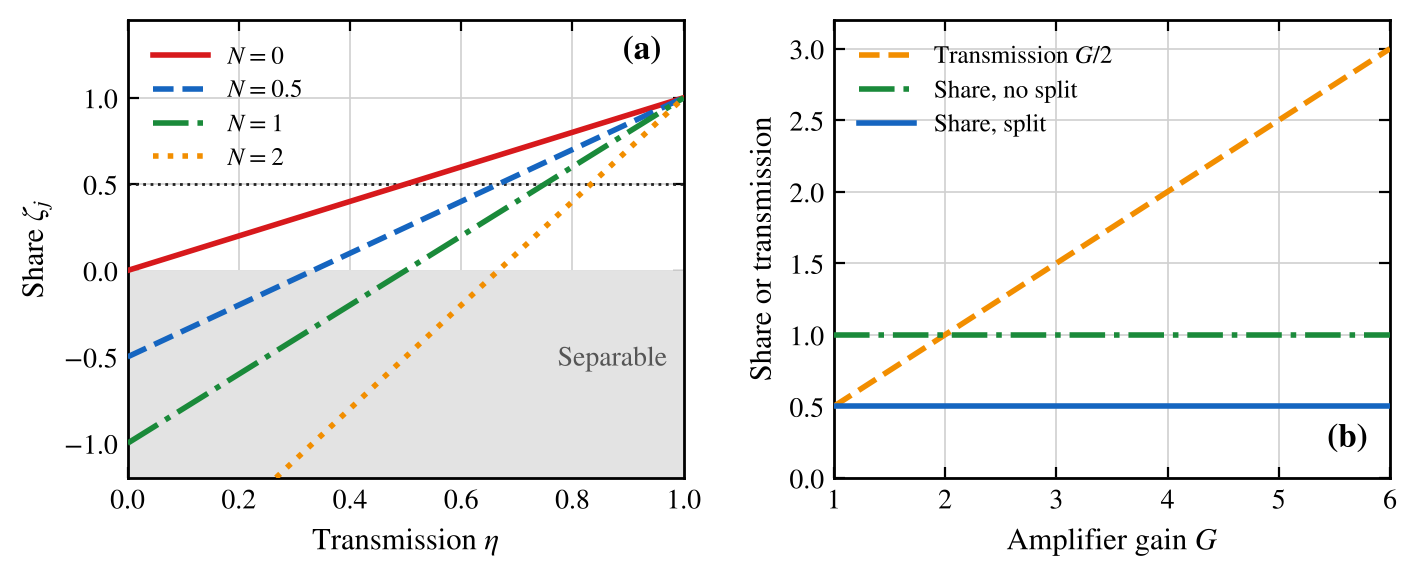

In [8]:
# ============================ Figure 2: shares of channels ============================
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.0))
eta = np.linspace(0, 1, 300)
grid(a1)
a1.axhspan(-1.2, 0, color=GRAY, zorder=1); a1.text(0.97, -0.55, 'Separable', ha='right', fontsize=10, color='#555555', zorder=2)
a1.axhline(0.5, color=DARK, lw=1, ls=':', zorder=2)
for N, col, ls in [(0, RED, '-'), (0.5, BLUE, '--'), (1, GREEN, '-.'), (2, ORANGE, ':')]:
    a1.plot(eta, eta - (1 - eta) * N, color=col, ls=ls, label='$N=%g$' % N, zorder=3)
a1.set_xlim(0, 1); a1.set_ylim(-1.2, 1.45); a1.set_xlabel(r'Transmission $\eta$'); a1.set_ylabel(r'Share $\zeta_j$')
a1.legend(loc='upper left', ncol=1, **LEG); plabel(a1, '(a)', 0.96, 0.97, ha='right')
G = np.linspace(1, 6, 300)
grid(a2)
a2.axhline(0.5, color=DARK, lw=1, ls=':', zorder=2)
a2.plot(G, G / 2, color=ORANGE, ls='--', label=r'Transmission $G/2$', zorder=3)
a2.plot(G, np.ones_like(G), color=GREEN, ls='-.', label='Share, no split', zorder=3)
a2.plot(G, 0.5 * np.ones_like(G), color=BLUE, label='Share, split', zorder=3)
a2.set_xlim(1, 6); a2.set_ylim(0, 3.2); a2.set_xlabel(r'Amplifier gain $G$'); a2.set_ylabel('Share or transmission')
a2.legend(loc='upper left', ncol=1, **LEG); plabel(a2, '(b)', 0.96, 0.05, ha='right'); a2.texts[-1].set_va('bottom')
fig.tight_layout(w_pad=1.6); fig.savefig(OUT + 'fig2.pdf'); plt.show()

## 3. The share bound (Sec. 4)

**Proposition 4(a) and Theorem 1.** For random Gaussian states, $\zeta_j>0$ agrees with the partial-transpose test of entanglement, and the shares of all neighbors satisfy $\sum_j\zeta_j^+\leq k$.

In [9]:
agree, tot, worst = 0, 0, -9
for t in range(300):
    k = int(rng.integers(1, 4)); m = int(rng.integers(1, 6)); e = int(rng.integers(0, 4)); n = max(k, m + e)
    V = state(k, rand_symp(n), rng.uniform(0.1, 1.5, size=k)); s = 0
    for j in range(m):
        VA, VAY, VY = blocks(V, k, j); z = share(VA, VAY, VY, k)[0]; s += max(z, 0)
        agree += (z > 1e-9) == ppt_entangled(VA, VAY, VY, k); tot += 1
    worst = max(worst, s - k)
print('share>0 <=> PPT-entangled agreement:', agree, '/', tot)
print('largest value of sum_j zeta_j^+ - k  :', worst)

share>0 <=> PPT-entangled agreement: 890 / 890
largest value of sum_j zeta_j^+ - k  : 2.2870594307278225e-14


**Proposition 5 (every allowed set of shares occurs).** Every vector of shares in $[0,1]$ with sum at most $k$ is realized by $k$ two-mode squeezed vacua and a passive network. We build the isometry from a rank-$k$ orthogonal projector with the prescribed diagonal (Schur-Horn theorem) and check the shares.

In [10]:
def projector_with_diag(dvec, k, tries=50):
    # find an orthogonal rank-k projector with diagonal dvec by minimizing the mismatch
    n = len(dvec)
    def f(p):
        A = p.reshape(n, k); Q, _ = np.linalg.qr(A); return np.sum((np.sum(Q**2, axis=1) - dvec)**2)
    best = min((minimize(f, rng.normal(size=n*k), method='BFGS') for _ in range(5)), key=lambda r: r.fun)
    Q, _ = np.linalg.qr(best.x.reshape(n, k)); return Q
for trial in range(3):
    k = int(rng.integers(2, 4)); m = int(rng.integers(k+1, 2*k+2))
    zt = rng.uniform(0, 1, size=m); zt *= min(1, (k - 0.3)/zt.sum())
    dvec = np.r_[zt, np.ones(k)*(k - zt.sum())/k]
    T = projector_with_diag(dvec, k)               # (m+k) x k isometry, row norms = dvec
    Qo, _ = np.linalg.qr(np.c_[T, rng.normal(size=(m+k, m))]); Qo[:, :k] = T   # complete to an orthogonal matrix
    S = np.kron(Qo, I2)                            # passive symplectic on partners + vacua
    V = state(k, S, np.ones(k)*0.7)
    got = [share(*blocks(V, k, j), k)[0] for j in range(m)]
    print('k=%d target' % k, np.round(zt, 4), '\n     got   ', np.round(got, 4))

k=3 target [0.4427 0.416  0.2501 0.5806 0.3079 0.7027] 
     got    [0.4427 0.4159 0.2501 0.5806 0.3079 0.7027]


k=2 target [0.1306 0.5238 0.1971 0.8485] 
     got    [0.1306 0.5238 0.1971 0.8485]


k=3 target [0.5807 0.8788 0.3753 0.1425] 
     got    [0.5807 0.8788 0.3753 0.1425]


### The tight-frame network (Sec. 4.3, Lemma 4)
The harmonic tight frame of $m=2k-1$ unit vectors in $\mathbb R^k$, Eqs. (29) to (31). Every neighbor sees a two-mode squeezed vacuum through loss of transmission $\eta=k/(2k-1)$, so all shares equal $\eta$ and the bound $\sum_j\zeta_j=k$ is reached. The last line gives the additional loss that all $2k-1$ neighbors tolerate while still steering the node (Sec. 5).

In [11]:
def frame(k, m):
    if k == 1: return np.ones((m, 1))
    U = []
    for j in range(m):
        v = []
        for r in range(1, k//2 + 1): v += [np.cos(2*np.pi*r*j/m), np.sin(2*np.pi*r*j/m)]
        if k % 2 == 1: v = [1/np.sqrt(2)] + v
        U.append(v[:k])
    U = np.array(U); return U/np.linalg.norm(U, axis=1, keepdims=True)

def frame_network_state(k, m, r):
    U = frame(k, m); T = np.sqrt(k/m)*U          # m x k, orthonormal columns
    Qo, _ = np.linalg.qr(np.c_[T, rng.normal(size=(m, m - k))]); Qo[:, :k] = T
    # Qo maps (partners, vacua) -> neighbors
    return state(k, np.kron(Qo, I2), np.ones(k)*r)

for k in range(1, 6):
    m = 2*k - 1; U = frame(k, m)
    assert np.allclose(U.T @ U, (m/k)*np.eye(k))
    V = frame_network_state(k, m, 0.8); z = [share(*blocks(V, k, j), k)[0] for j in range(m)]
    print(f'k={k}: shares =', np.round(z, 6), ' sum =', round(sum(z), 6), ' (eta = %.4f)' % (k/m))
print('Additional loss tolerated by all 2k-1 neighbors, 1/(2k):', {k: '%.0f%%' % (100/(2*k)) for k in (2, 3, 5)})

k=1: shares = [1.]  sum = 1.0  (eta = 1.0000)
k=2: shares = [0.666667 0.666667 0.666667]  sum = 2.0  (eta = 0.6667)
k=3: shares = [0.6 0.6 0.6 0.6 0.6]  sum = 3.0  (eta = 0.6000)
k=4: shares = [0.571429 0.571429 0.571429 0.571429 0.571429 0.571429 0.571429]  sum = 4.0  (eta = 0.5714)
k=5: shares = [0.555556 0.555556 0.555556 0.555556 0.555556 0.555556 0.555556 0.555556
 0.555556]  sum = 5.0  (eta = 0.5556)
Additional loss tolerated by all 2k-1 neighbors, 1/(2k): {2: '25%', 3: '17%', 5: '10%'}


## 4. Exact count for steering (Sec. 5)

**Theorem 2.** In random Gaussian networks the number of neighbors with $\zeta_j>1/2$, that is, of neighbors that steer the node by Gaussian measurements, never exceeds $2k-1$, and the tight-frame network above reaches $2k-1$.

**Proposition 6 (neighbors with several modes).** A neighbor $Y$ with $\ell$ modes steers the node by Gaussian measurements exactly when $Q_Y=V_Y-V_{YA}(V_A+i\Omega_A)^{-1}V_{AY}$ is not positive semidefinite. We follow the proof of the paper step by step. From an eigenvector $z$ of $Q_Y$ with negative eigenvalue we form $\mathbf e=\sqrt2\,\mathrm{Im}\,z$ and $\mathbf f=\sqrt2\,\mathrm{Re}\,z$, complete them to a symplectic basis of $Y$, and compute the share of the first mode of this basis. It must exceed one half and satisfy $1-2\zeta_{Y_1}\leq z^\dagger Q_Yz$. We also check that the number of steering two-mode neighbors never exceeds $2k-1$.

In [12]:
# Theorem 2: count of single-mode neighbors with share above 1/2 in random networks
most = {}
for t in range(400 if not QUICK else 150):
    k = int(rng.integers(1, 4)); m = int(rng.integers(2, 4*k + 2)); n = max(k, m + int(rng.integers(0, 3)))
    V = state(k, rand_symp(n, 0.35), rng.uniform(0.3, 2.0, size=k))
    N = sum(share(*blocks(V, k, j), k)[0] > 0.5 for j in range(m))
    most[k] = max(most.get(k, 0), N)
print('largest number of neighbors with zeta > 1/2 found in random networks:', most, '  bound 2k-1:', {k: 2*k - 1 for k in most})

# Proposition 6: neighbors with two modes
def sympl_complete(e, f, l):
    # complete a canonical pair (e, f), e^T Omega f = 1, to a symplectic basis given by the rows of S
    Ol = Om(l); A, B = [e], [f]
    def proj(v):
        for a, b in zip(A, B): v = v - (a @ Ol @ v)*b + (b @ Ol @ v)*a
        return v
    cands = [proj(x) for x in np.eye(2*l)]
    while len(A) < l:
        cands = [proj(x) for x in cands]; cands.sort(key=lambda x: -np.linalg.norm(x)); a = cands.pop(0)
        cands = [proj(x) for x in cands]; vals = [abs(a @ Ol @ x) for x in cands]; b = cands.pop(int(np.argmax(vals)))
        b = b/(a @ Ol @ b); A.append(a); B.append(b)
    S = np.array([v for ab in zip(A, B) for v in ab])
    assert np.allclose(S @ Ol @ S.T, Ol, atol=1e-8); return S
l = 2; checked, steer, worst_gap, most2 = 0, 0, 9, {}
for t in range(300 if not QUICK else 120):
    k = int(rng.integers(1, 3)); mneigh = int(rng.integers(1, 2*k + 3)); n = max(k, l*mneigh + int(rng.integers(0, 3)))
    V = state(k, rand_symp(n, 0.35), rng.uniform(0.3, 2.0, size=k)); Nst = 0
    for j in range(mneigh):
        sel = list(range(2*k)) + list(range(2*k + 2*l*j, 2*k + 2*l*(j + 1)))
        W = V[np.ix_(sel, sel)]; VA, VAY, VY = W[:2*k, :2*k], W[:2*k, 2*k:], W[2*k:, 2*k:]
        Q = VY - VAY.T @ np.linalg.inv(VA + 1j*Om(k)) @ VAY; Q = (Q + Q.conj().T)/2
        w, U = np.linalg.eigh(Q); checked += 1
        if w[0] > -1e-9: continue
        z = U[:, 0]; nz = np.real(z.conj() @ (1j*Om(l)) @ z)
        assert nz > 0, 'negative direction must have positive symplectic norm (Eq. multibound)'
        z = z/np.sqrt(nz); e = np.sqrt(2)*z.imag; f = np.sqrt(2)*z.real
        S = sympl_complete(e, f, l); L = np.eye(2*k + 2*l); L[2*k:, 2*k:] = S; W2 = L @ W @ L.T
        zY1 = share(W2[:2*k, :2*k], W2[:2*k, 2*k:2*k + 2], W2[2*k:2*k + 2, 2*k:2*k + 2], k)[0]
        qz = np.real(z.conj() @ Q @ z); assert zY1 > 0.5 and 1 - 2*zY1 <= qz + 1e-9
        worst_gap = min(worst_gap, zY1 - 0.5); steer += 1; Nst += 1
    most2[k] = max(most2.get(k, 0), Nst)
print(f'two-mode neighbors checked: {checked}, steering ones: {steer}; every steering neighbor has a mode with share > 1/2 (smallest excess {worst_gap:.2e})')
print('largest number of steering two-mode neighbors found:', most2, '  bound 2k-1:', {k: 2*k - 1 for k in most2})

largest number of neighbors with zeta > 1/2 found in random networks: {2: np.int64(2), 3: np.int64(3), 1: np.int64(1)}   bound 2k-1: {2: 3, 3: 5, 1: 1}
two-mode neighbors checked: 872, steering ones: 167; every steering neighbor has a mode with share > 1/2 (smallest excess 1.67e-03)
largest number of steering two-mode neighbors found: {1: 1, 2: 2}   bound 2k-1: {1: 1, 2: 3}


## 5. Remote Wigner negativity (Sec. 6)

**Theorem 5.** Photon statistics of the steered modes in $|\Phi_k\rangle\propto\prod_j\hat g_j^\dagger|0\rangle$, the value $W_{Y_j}(0)=X_k/(2\pi)$ of Eq. (51), the bound $-1/(2\pi(2k-1)^2)$ of Eq. (49) and the exact value $-7/(54\pi)$ for $k=2$, Eq. (54).

In [13]:
def poly_state(vecs, k):
    poly = {tuple([0]*k): 1.0}
    for u in vecs:
        new = {}
        for occ, a in poly.items():
            for l in range(k):
                if abs(u[l]) < 1e-15: continue
                o = list(occ); o[l] += 1; o = tuple(o); new[o] = new.get(o, 0) + a*u[l]
        poly = new
    return poly
def state_from_modes(vecs, k):
    st = {o: a*sqrt(np.prod([factorial(x) for x in o])) for o, a in poly_state(vecs, k).items()}
    nrm = sqrt(sum(abs(v)**2 for v in st.values())); return {o: v/nrm for o, v in st.items()}
def completion(u):
    k = len(u); Q, _ = np.linalg.qr(np.column_stack([u, np.eye(k)])); Q = Q[:, :k]
    if np.dot(Q[:, 0], u) < 0: Q[:, 0] *= -1
    return Q
def pn_dist(k, U, j):
    O = completion(U[j]); m = len(U); st = state_from_modes([U[s] @ O for s in range(m)], k)
    p = np.zeros(m + 1)
    for o, a in st.items(): p[o[0]] += abs(a)**2
    return p

wd = {}
for k in range(1, 7):
    m = 2*k - 1; varrho = 1/m
    p = np.array([0, 1.]) if k == 1 else pn_dist(k, frame(k, m), 0)
    sym = 0 if k == 1 else max(np.abs(pn_dist(k, frame(k, m), j) - p).max() for j in range(m))
    X = sum(p[n]*(-varrho)**n for n in range(len(p)))
    wd[str(k)] = dict(p1=p[1], W0=X/(2*np.pi), bound=-1/(2*np.pi*m**2), mean=p @ np.arange(len(p)), sym=sym, p0=p[0])
    print(f"k={k}: p0={p[0]:.0e} p1={p[1]:.4f} (>=1/k={1/k:.3f})  <n>={wd[str(k)]['mean']:.4f} (2-1/k={2-1/k:.4f})"
          f"  W(0)={X/(2*np.pi):.5f}  bound={-1/(2*np.pi*m**2):.5f}  symmetry dev={sym:.0e}")
print('k=2 exact value -7/(54 pi) =', -7/(54*np.pi), '  parity 2*pi*W(0) =', 2*np.pi*wd['2']['W0'], '= -7/27 =', -7/27)

k=1: p0=0e+00 p1=1.0000 (>=1/k=1.000)  <n>=1.0000 (2-1/k=1.0000)  W(0)=-0.15915  bound=-0.15915  symmetry dev=0e+00
k=2: p0=0e+00 p1=0.7500 (>=1/k=0.500)  <n>=1.5000 (2-1/k=1.5000)  W(0)=-0.04126  bound=-0.01768  symmetry dev=8e-16
k=3: p0=0e+00 p1=0.5829 (>=1/k=0.333)  <n>=1.6667 (2-1/k=1.6667)  W(0)=-0.01702  bound=-0.00637  symmetry dev=3e-16
k=4: p0=0e+00 p1=0.5433 (>=1/k=0.250)  <n>=1.7500 (2-1/k=1.7500)  W(0)=-0.01161  bound=-0.00325  symmetry dev=1e-15
k=5: p0=0e+00 p1=0.5179 (>=1/k=0.200)  <n>=1.8000 (2-1/k=1.8000)  W(0)=-0.00869  bound=-0.00196  symmetry dev=4e-16


k=6: p0=0e+00 p1=0.5036 (>=1/k=0.167)  <n>=1.8333 (2-1/k=1.8333)  W(0)=-0.00694  bound=-0.00132  symmetry dev=3e-15
k=2 exact value -7/(54 pi) = -0.04126239265345435   parity 2*pi*W(0) = -0.2592592592592592 = -7/27 = -0.25925925925925924


### Linear optics, rates and imperfections (Sec. 6.7 and Sec. 9.3)

In [14]:
# Rates of the ideal projection and of its linear-optical realization
for k in (2, 3):
    m = 2*k - 1; q = m/(m + k); p = (1 - q)**k*q**m
    Nk = sum(abs(a)**2*np.prod([factorial(x) for x in o]) for o, a in poly_state(frame(k, m), k).items())
    eta = k/m; dB = 10*np.log10(np.exp(2*np.arctanh(np.sqrt(q))))
    print(f'k={k}: ideal p_max={p:.4f} at q_v={q:.3f} ({dB:.1f} dB); prefactor eta^m N_k={eta**m*Nk:.4f}; linear-optics rate={eta**m*Nk*p:.4f}')

# Imperfect heralding detectors of efficiency eta_s (loss on the node before an ideal projection)
def W0_detector(k, qv, eta_s):
    m = 2*k - 1; eta = k/m; v = (1 + qv)/(1 - qv); s2 = v*v - 1; w = eta*v + 1 - eta
    d = v - eta*s2/w                                   # conditional symplectic eigenvalue of the steered mode
    d2, v2 = eta_s*d + 1 - eta_s, eta_s*v + 1 - eta_s
    qd, qv2 = (d2 - 1)/(d2 + 1), (v2 - 1)/(v2 + 1)
    p = np.array([0, 1.]) if k == 1 else pn_dist(k, frame(k, m), 0)
    X = sum(p[n]*(qd/qv2)**n for n in range(len(p)))
    return (1 - qd)/(1 - qv2)*X/(2*np.pi*w)
k = 2; qopt = 3/5
for es in (1.0, 0.9, 0.7):
    W0 = W0_detector(k, qopt, es); print(f'k=2, eta_s={es}: W(0)={W0:.4f}, parity={2*np.pi*W0:.3f}')
# Number of heralded events needed to resolve the parity at 3 sigma (shots give +-1)
for par in (-7/27, 2*np.pi*W0_detector(2, qopt, 0.9)):
    N = 9*(1 - par**2)/par**2; print(f'parity {par:.3f}: about {N:.0f} heralded events, {N/0.015:.0f} runs at 1.5% rate')

k=2: ideal p_max=0.0346 at q_v=0.600 (9.0 dB); prefactor eta^m N_k=0.4444; linear-optics rate=0.0154
k=3: ideal p_max=0.0050 at q_v=0.625 (9.3 dB); prefactor eta^m N_k=0.1952; linear-optics rate=0.0010
k=2, eta_s=1.0: W(0)=-0.0413, parity=-0.259
k=2, eta_s=0.9: W(0)=-0.0349, parity=-0.219
k=2, eta_s=0.7: W(0)=-0.0243, parity=-0.153
parity -0.259: about 125 heralded events, 8327 runs at 1.5% rate
parity -0.219: about 179 heralded events, 11910 runs at 1.5% rate


### Figure 3: remote Wigner negativity

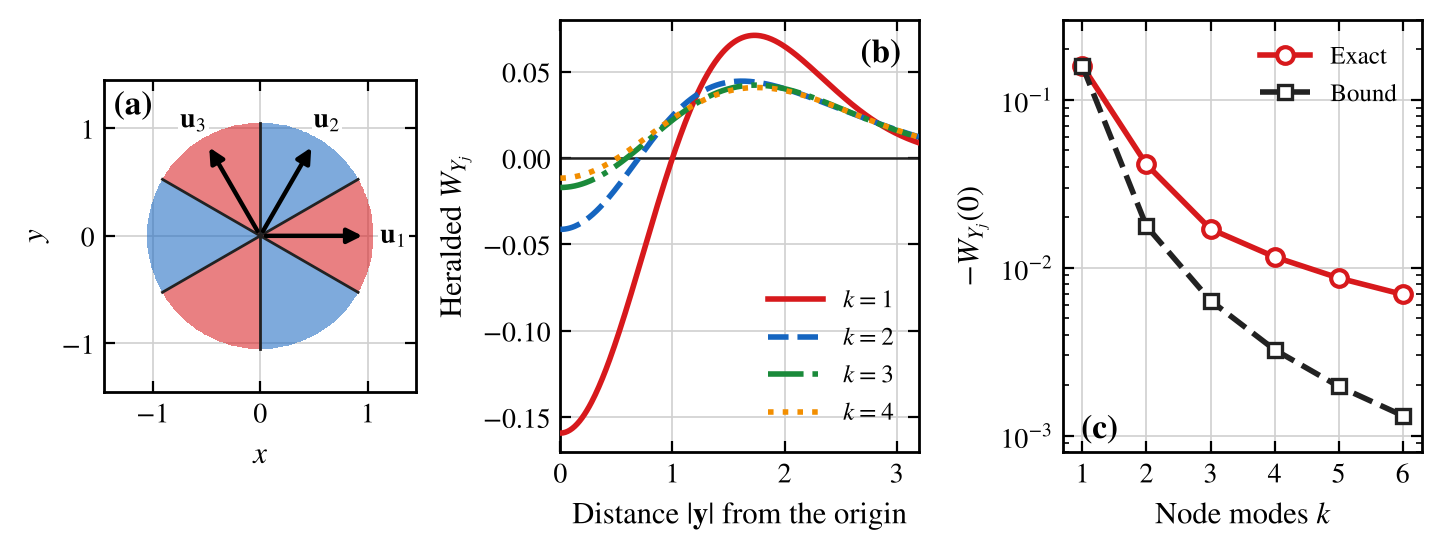

In [15]:
# ============================ Figure 3 (in paper): remote Wigner negativity ============================
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(7.2, 2.7), gridspec_kw={'width_ratios': [1, 1.15, 1.15]})
# (a) sign pattern of prod_j (u_j . x) for k=2
grid(a1)
X, Y = np.meshgrid(np.linspace(-1.45, 1.45, 401), np.linspace(-1.45, 1.45, 401))
P = -(X ** 3 - 3 * X * Y ** 2) / 4; R = np.hypot(X, Y)
Pm = np.ma.masked_where(R > 1.05, P)
a1.contourf(X, Y, np.sign(Pm), levels=[-2, 0, 2], colors=[RED, BLUE], alpha=0.55, zorder=1)
for j in range(3):
    th = j * np.pi / 3 + np.pi / 2
    a1.plot([-1.05 * np.cos(th), 1.05 * np.cos(th)], [-1.05 * np.sin(th), 1.05 * np.sin(th)], color=DARK, lw=1.0, zorder=2)
for j in range(3):
    th = j * np.pi / 3
    a1.annotate('', xy=(1.0 * np.cos(th), 1.0 * np.sin(th)), xytext=(0, 0),
                arrowprops=dict(arrowstyle='-|>', color='black', lw=1.6, mutation_scale=11), zorder=4)
for j in range(3):
    th = j * np.pi / 3
    a1.text(1.24 * np.cos(th), 1.24 * np.sin(th), r'$\mathbf{u}_%d$' % (j + 1), fontsize=10, ha='center', va='center', zorder=5,
            bbox=dict(fc='white', ec='none', pad=0.6))
a1.set_xlim(-1.45, 1.45); a1.set_ylim(-1.45, 1.45); a1.set_aspect('equal')
a1.set_xlabel('$x$'); a1.set_ylabel('$y$'); a1.set_xticks([-1, 0, 1]); a1.set_yticks([-1, 0, 1])
plabel(a1, '(a)', 0.03, 0.97)
# (b) heralded Wigner function vs |y|
grid(a2)
rs = np.linspace(0, 3.2, 300)
for k in range(1, 5):
    m = 2 * k - 1; et = k / m
    pk = np.array([0, 1.]) if k == 1 else pn_dist(k, frame(k, m), 0)
    PY = np.zeros(len(pk))
    for N_, pN in enumerate(pk):
        for n_ in range(N_ + 1):
            PY[n_] += pN * comb(N_, n_) * et ** n_ * (1 - et) ** (N_ - n_)
    W = sum(PY[n_] * (-1) ** n_ * np.exp(-rs ** 2 / 2) * eval_laguerre(n_, rs ** 2) for n_ in range(len(PY))) / (2 * np.pi)
    a2.plot(rs, W, color=COLS[k - 1], ls=['-', '--', '-.', ':'][k - 1], label='$k=%d$' % k, zorder=3)
a2.axhline(0, color=DARK, lw=0.9, zorder=2)
a2.set_xlim(0, 3.2); a2.set_ylim(-0.17, 0.08); a2.set_xlabel(r'Distance $|\mathbf{y}|$ from the origin'); a2.set_ylabel(r'Heralded $W_{Y_j}$')
a2.legend(loc='lower right', ncol=1, fontsize=9, handlelength=2.2, borderaxespad=0.6); plabel(a2, '(b)', 0.95, 0.96, ha='right')
# (c) W(0) vs k
grid(a3)
ks = np.arange(1, 7)
W0 = np.array([wd[str(k)]['W0'] for k in ks]); Bd = np.array([wd[str(k)]['bound'] for k in ks])
a3.semilogy(ks, -W0, 'o-', color=RED, ms=6, mfc='white', mec=RED, mew=1.5, label='Exact', zorder=3)
a3.semilogy(ks, -Bd, 's--', color=DARK, ms=5, mfc='white', mew=1.2, label='Bound', zorder=3)
a3.set_xlabel(r'Node modes $k$'); a3.set_ylabel(r'$-W_{Y_j}(0)$'); a3.set_xticks(ks); a3.set_xlim(0.7, 6.3); a3.set_ylim(8e-4, 0.3)
a3.legend(loc='upper right', ncol=1, fontsize=9, borderaxespad=0.6); plabel(a3, '(c)', 0.05, 0.09)
fig.subplots_adjust(left=0.075, right=0.99, bottom=0.17, top=0.97, wspace=0.42)
fig.savefig(OUT + 'fig3.pdf'); plt.show()

## 6. Arbitrary measurements and Bell nonlocality (Sec. 7)

### Two settings, a CHSH violation for every neighbor (Sec. 7.3, Theorem 7)
Qubit-block observables $O_\theta=(\cos\theta\,\sigma_z+\sin\theta\,\sigma_x)\oplus\mathbb 1_{n\geq2}$ of Eq. (62) on a two-mode squeezed vacuum seen through loss, compared with displaced parity, whose correlations follow in closed form from the Gaussian Wigner function. The first line compares the proven bound (64) with the settings of Theorem 7 for $k=2$.

In [16]:
def lossy_tmsv(lam, eta, D=8):
    # TMSV truncated at D-1 photons, loss eta on the second mode (unnormalized)
    rho = np.zeros((D*D, D*D)); c = sqrt(1 - lam**2)
    for l in range(D):
        psi = np.zeros(D*D)
        for n in range(l, D): psi[n*D + (n - l)] += c*lam**n*sqrt(comb(n, l)*eta**(n - l)*(1 - eta)**l)
        rho += np.outer(psi, psi)
    return rho
def obs(th, D=8):
    O = np.eye(D); O[:2, :2] = [[np.cos(th), np.sin(th)], [np.sin(th), -np.cos(th)]]; return O
def chsh_q(rho, p, D=8):
    a, a2, b, b2 = p; E = lambda x, y: np.trace(rho @ np.kron(obs(x, D), obs(y, D)))
    return E(a, b) + E(a2, b) + E(a, b2) - E(a2, b2)
def V2(v, eta):
    s = np.sqrt(v*v - 1); w = eta*v + 1 - eta; c = np.sqrt(eta)*s
    return np.block([[v*I2, c*Z], [c*Z, w*I2]])
def chsh_parity(p, V):
    Vi = np.linalg.inv(V); dt = np.sqrt(np.linalg.det(V)); a, a2, b, b2 = p[0:2], p[2:4], p[4:6], p[6:8]
    E = lambda x, y: np.exp(-0.5*np.r_[x, y] @ Vi @ np.r_[x, y])/dt
    return E(a, b) + E(a2, b) + E(a, b2) - E(a2, b2)

# Theorem 7 settings for k=2 and the proven bound
k = 2; eta = k/(2*k-1); lam = np.sqrt(1/(8*(2*k-1))); D = 15
rho = lossy_tmsv(lam, eta, D); rho /= np.trace(rho)
best = max(-minimize(lambda p: -chsh_q(rho, [0, np.pi/2, p[0], -p[0]], D), [x]).fun for x in (0.2, 0.5, 1.0))
print('k=2: bound 2+1/(8*9) =', 2 + 1/72, ' Theorem-7 settings (phi optimized):', round(best, 4))

def qbest(eta, lams, D=10, starts=3):
    out = 2
    for lam in lams:
        rho = lossy_tmsv(lam, eta, D); rho /= np.trace(rho)
        for _ in range(starts):
            r = minimize(lambda p: -chsh_q(rho, p, D), np.array([0, np.pi/2, np.pi/4, -np.pi/4]) + rng.normal(size=4)*0.2)
            out = max(out, -r.fun)
    return out
def pbest(eta, starts=12):
    out = 2
    for _ in range(starts):
        x0 = np.r_[rng.uniform(-3, 3), rng.normal(size=8)*0.3]
        r = minimize(lambda x: -chsh_parity(x[1:], V2(1 + np.exp(x[0]), eta)), x0, method='BFGS'); out = max(out, -r.fun)
    return out
etas = np.linspace(0.5, 1, 11 if QUICK else 26)
lam_grid = np.linspace(0.02, 0.6, 12 if QUICK else 30)
d = {'eta': list(etas), 'q': [qbest(e, lam_grid) for e in etas], 'p': [pbest(e, 6 if QUICK else 12) for e in etas]}
for e, q, p in zip(etas, d['q'], d['p']): print(f'eta={e:.3f}: qubit-block B={q:.4f} (B-2={q-2:.2e})   displaced parity B={p:.4f} (B-2={p-2:.2e})')

k=2: bound 2+1/(8*9) = 2.013888888888889  Theorem-7 settings (phi optimized): 2.0461


eta=0.500: qubit-block B=2.0000 (B-2=0.00e+00)   displaced parity B=2.0000 (B-2=0.00e+00)
eta=0.520: qubit-block B=2.0030 (B-2=2.98e-03)   displaced parity B=2.0000 (B-2=1.80e-05)
eta=0.540: qubit-block B=2.0112 (B-2=1.12e-02)   displaced parity B=2.0001 (B-2=1.37e-04)
eta=0.560: qubit-block B=2.0237 (B-2=2.37e-02)   displaced parity B=2.0004 (B-2=4.41e-04)
eta=0.580: qubit-block B=2.0398 (B-2=3.98e-02)   displaced parity B=2.0010 (B-2=1.00e-03)
eta=0.600: qubit-block B=2.0588 (B-2=5.88e-02)   displaced parity B=2.0019 (B-2=1.88e-03)
eta=0.620: qubit-block B=2.0803 (B-2=8.03e-02)   displaced parity B=2.0031 (B-2=3.14e-03)
eta=0.640: qubit-block B=2.1036 (B-2=1.04e-01)   displaced parity B=2.0048 (B-2=4.82e-03)
eta=0.660: qubit-block B=2.1285 (B-2=1.28e-01)   displaced parity B=2.0070 (B-2=6.98e-03)
eta=0.680: qubit-block B=2.1546 (B-2=1.55e-01)   displaced parity B=2.0097 (B-2=9.68e-03)
eta=0.700: qubit-block B=2.1814 (B-2=1.81e-01)   displaced parity B=2.0130 (B-2=1.30e-02)
eta=0.720:

In [17]:
# CHSH value of the network neighbors versus squeezing (Fig. 4b)
def S_of(lam, eta, D=14):
    rho = lossy_tmsv(lam, eta, D); rho /= np.trace(rho)
    return max(-minimize(lambda p: -chsh_q(rho, p, D), np.array([0, np.pi/2, 0.4, -0.4]) + rng.random(4)*0.2).fun for _ in range(2))
dbs = np.linspace(0.05, 12, 20 if QUICK else 40)
nd = {'dB': list(dbs)}
for k in [1, 2, 3, 4]:
    eta = k/(2*k - 1); nd['S%d' % k] = [S_of(np.tanh(db/(20*np.log10(np.e))), eta, 10 if QUICK else 14) for db in dbs]
    i = int(np.argmax(nd['S%d' % k])); print(f'k={k}: max CHSH {max(nd["S%d" % k]):.3f} at {dbs[i]:.1f} dB')


k=1: max CHSH 2.584 at 6.5 dB


k=2: max CHSH 2.137 at 4.6 dB


k=3: max CHSH 2.059 at 3.7 dB


k=4: max CHSH 2.032 at 3.1 dB


### Figure 4: CHSH violation

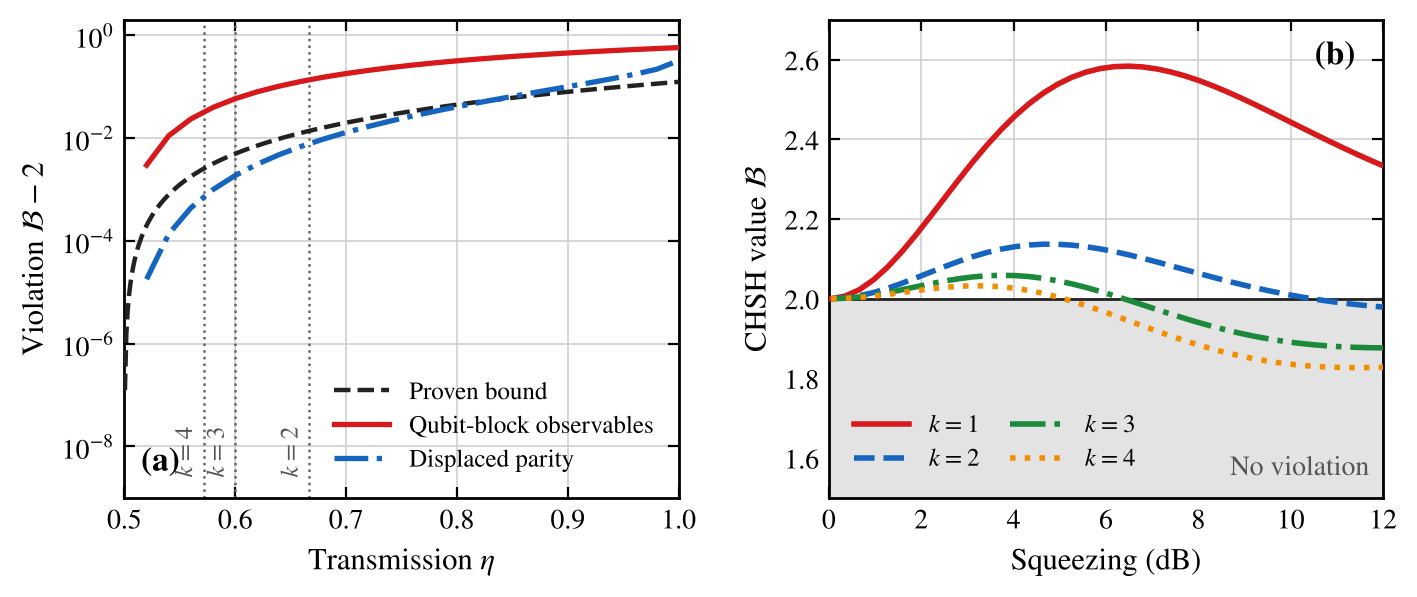

In [18]:
# ============================ Figure 4: CHSH ============================
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.1))
e = np.array(d['eta']); q = np.array(d['q']) - 2; p = np.array(d['p']) - 2; msk = e > 0.501
ee = np.linspace(0.5005, 1, 400)
grid(a1)
a1.semilogy(ee, (2 * ee - 1) ** 2 / 8, '--', color=DARK, lw=1.6, label='Proven bound', zorder=3)
a1.semilogy(e[msk], q[msk], '-', color=RED, lw=1.9, label='Qubit-block observables', zorder=4)
a1.semilogy(e[msk], p[msk], '-.', color=BLUE, lw=1.9, label='Displaced parity', zorder=4)
YMIN = 1e-9
for k in [2, 3, 4]:
    et = k / (2 * k - 1); a1.axvline(et, color=MID, lw=0.9, ls=':', zorder=2)
    a1.text(et - 0.004, 2.5e-9, '$k=%d$' % k, fontsize=9, color='#555555', rotation=90, va='bottom', ha='right', zorder=2)
a1.set_xlim(0.5, 1.0); a1.set_ylim(YMIN, 2); a1.set_xlabel(r'Transmission $\eta$'); a1.set_ylabel(r'Violation $\mathcal{B}-2$')
a1.legend(loc='lower right', ncol=1, **LEG); plabel(a1, '(a)', 0.03, 0.04); a1.texts[-1].set_va('bottom')
db = np.array(nd['dB'])
grid(a2)
a2.axhspan(1.5, 2, color=GRAY, zorder=1); a2.text(11.7, 1.54, 'No violation', ha='right', va='bottom', fontsize=10, color='#555555', zorder=2)
a2.axhline(2, color=DARK, lw=1, zorder=2)
for i, k in enumerate(['1', '2', '3', '4']):
    a2.plot(db, nd['S' + k], color=COLS[i], ls=['-', '--', '-.', ':'][i], label='$k=%s$' % k, zorder=3)
a2.set_xlim(0, 12); a2.set_ylim(1.5, 2.7); a2.set_xlabel('Squeezing (dB)'); a2.set_ylabel(r'CHSH value $\mathcal{B}$')
a2.legend(loc='lower left', ncol=2, columnspacing=1.2, **LEG); plabel(a2, '(b)', 0.95, 0.96, ha='right')
fig.tight_layout(w_pad=1.6); fig.savefig(OUT + 'fig4.pdf'); plt.show()

### Three and four settings (Sec. 7.4)
Steering robustness of the node's assemblage when the neighbor measures qubit-block observables along two directions, the three Pauli directions or the four directions of a regular tetrahedron. The two-mode squeezed vacuum is truncated at three photons before the loss, which is a filtering of the steered node only, so a positive robustness certifies steering of the original state. The semidefinite programs are solved with SCS through CVXPY.

In [19]:
import cvxpy as cp
sx = np.array([[0, 1], [1, 0]]); sy = np.array([[0, -1j], [1j, 0]]); sz = np.diag([1., -1.])
def proj_block(nvec, D, sign):
    O = np.eye(D, dtype=complex); O[:2, :2] = nvec[0]*sx + nvec[1]*sy + nvec[2]*sz
    return (np.eye(D) + sign*O)/2
def assemblage(rho, D, dirs):
    R = rho.reshape(D, D, D, D)
    return [np.einsum('iajb,ba->ij', R, proj_block(dv, D, s)) for dv in dirs for s in (+1, -1)]
def robustness(sig, ny):
    D = sig[0].shape[0]; lams = list(itertools.product([0, 1], repeat=ny))
    S = [cp.Variable((D, D), hermitian=True) for _ in lams]; cons = [s >> 0 for s in S]
    for y in range(ny):
        for b in range(2):
            cons.append(sum(S[i] for i, l in enumerate(lams) if l[y] == b) - sig[2*y + b] >> 0)
    prob = cp.Problem(cp.Minimize(cp.real(sum(cp.trace(s) for s in S))), cons)
    prob.solve(solver='SCS', eps=1e-9, max_iters=200000); return prob.value - 1
def dirs_n(n):
    if n == 2: return [np.array([1, 0, 0]), np.array([0, 0, 1])]
    if n == 3: return [np.array([1, 0, 0]), np.array([0, 1, 0]), np.array([0, 0, 1])]
    if n == 4: return list(np.array([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]])/np.sqrt(3))
def SRmax(eta, n, D=4):
    f = lambda lam: -robustness(assemblage(lossy_tmsv(lam, eta, D)/np.trace(lossy_tmsv(lam, eta, D)), D, dirs_n(n)), n)
    r = minimize_scalar(f, bounds=(0.05, 0.7), method='bounded', options={'xatol': 1e-3}); return -r.fun, r.x
grid_sr = {2: [0.48, 0.5, 0.52, 0.55, 0.6, 0.65, 0.7],
           3: [0.32, 0.335, 0.35, 0.375, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7],
           4: [0.3, 0.31, 0.32, 0.335, 0.35, 0.375, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7]}
if QUICK: grid_sr = {2: [0.48, 0.52, 0.6, 0.7], 3: [0.32, 0.335, 0.4, 0.5, 0.6, 0.7], 4: [0.3, 0.32, 0.35, 0.45, 0.55, 0.7]}
sr = {}
for n in [2, 3, 4]:
    sr[str(n)] = []
    for eta in grid_sr[n]:
        v, l = SRmax(eta, n); sr[str(n)].append((eta, max(v, 0.0), l)); print(f'n={n} eta={eta}: robustness={v:.2e}')

n=2 eta=0.48: robustness=8.10e-14


n=2 eta=0.5: robustness=3.74e-12


n=2 eta=0.52: robustness=3.85e-03


n=2 eta=0.55: robustness=1.06e-02


n=2 eta=0.6: robustness=2.26e-02


n=2 eta=0.65: robustness=3.51e-02


... (21 outputs left out)

n=4 eta=0.55: robustness=6.49e-02


n=4 eta=0.6: robustness=8.04e-02


n=4 eta=0.65: robustness=9.63e-02


n=4 eta=0.7: robustness=1.12e-01


Threshold near $\eta=1/3$, effect of the Fock cutoff, and the frame network with $3k-1$ neighbors at $\eta=k/(3k-1)$, Eq. (65).

In [20]:
# Threshold check near 1/3 and the frame network with 3k-1 neighbors
for eta in ([0.3335, 0.332] if QUICK else [0.338, 0.335, 0.3335, 0.332, 0.33]):
    print(f'n=3 eta={eta}: SR={SRmax(eta, 3)[0]:.2e}')
# effect of the cutoff (three vs five photons)
for eta in (0.4, 0.35):
    print(f'cutoff check eta={eta}: D=4 SR={SRmax(eta, 3, 4)[0]:.5e}, D=6 SR={SRmax(eta, 3, 6)[0]:.5e}')
net = []
for k in ([1, 2, 3, 5, 10, 50] if QUICK else [1, 2, 3, 4, 5, 10, 20, 50]):
    eta = k/(3*k - 1); v, l = SRmax(eta, 3); net.append((k, eta, v, l))
    print(f'k={k}, m={3*k-1}, eta={eta:.4f}: three-setting robustness={v:.3e}  (k^2*SR={k*k*v:.3f})')

n=3 eta=0.338: SR=1.96e-04


n=3 eta=0.335: SR=2.69e-05


n=3 eta=0.3335: SR=3.37e-07


n=3 eta=0.332: SR=1.04e-12


n=3 eta=0.33: SR=9.77e-15


cutoff check eta=0.4: D=4 SR=1.56420e-02, D=6 SR=1.55398e-02


... (5 outputs left out)

k=5, m=14, eta=0.3571: three-setting robustness=3.471e-03  (k^2*SR=0.087)


k=10, m=29, eta=0.3448: three-setting robustness=1.021e-03  (k^2*SR=0.102)


k=20, m=59, eta=0.3390: three-setting robustness=2.810e-04  (k^2*SR=0.112)


k=50, m=149, eta=0.3356: three-setting robustness=4.786e-05  (k^2*SR=0.120)


### Certificates for the three-setting results (Appendix I, Table 5)
The dual variables of the robustness program define a steering inequality $\sum_{b,y}\mathrm{tr}(F_{b|y}\sigma_{b|y})\leq1$, valid for every assemblage with a local hidden-state model when $F_{b|y}\geq0$ and $\sum_y F_{\lambda_y|y}\leq\mathbb 1$ for all deterministic assignments $\lambda$. We extract them, make them exactly positive definite, rescale them so that the local bound holds, and verify the bound and the violation in 50-digit arithmetic with `mpmath`.

In [21]:
from mpmath import mp, matrix, mpf
mp.dps = 50
def sr_dual(sig, ny):
    D = sig[0].shape[0]; lams = list(itertools.product([0, 1], repeat=ny))
    S = [cp.Variable((D, D), hermitian=True) for _ in lams]; cons = [s >> 0 for s in S]; dom = []
    for y in range(ny):
        for b in range(2):
            c = sum(S[i] for i, l in enumerate(lams) if l[y] == b) - sig[2*y + b] >> 0; cons.append(c); dom.append(c)
    prob = cp.Problem(cp.Minimize(cp.real(sum(cp.trace(s) for s in S))), cons)
    prob.solve(solver='SCS', eps=1e-10, max_iters=400000)
    return prob.value - 1, [np.array(c.dual_value) for c in dom], lams
def certify(sig, ny, F, lams):
    F = [(f + f.conj().T)/2 for f in F]
    F = [(lambda w, V: (V*np.clip(w, 0, None)) @ V.conj().T)(*np.linalg.eigh(f)) + 1e-12*np.eye(f.shape[0]) for f in F]
    F = [f/max(np.linalg.eigvalsh(sum(F[2*y + l[y]] for y in range(ny))).max() for l in lams) for f in F]
    M = lambda a: matrix([[mp.mpc(complex(x)) for x in row] for row in a])
    Fm = [M(f) for f in F]; Sm = [M(s) for s in sig]; D = F[0].shape[0]
    lb = max(max(mp.re(x) for x in mp.eighe((lambda A: (A + A.H)/2)(sum((Fm[2*y + l[y]] for y in range(ny)), matrix(D))))[0]) for l in lams)
    val = sum(mp.re(sum(Fm[i][a, b]*Sm[i][b, a] for a in range(D) for b in range(D))) for i in range(len(F)))
    minF = min(min(mp.re(x) for x in mp.eighe((f + f.H)/2)[0]) for f in Fm)
    return val, lb, minF
for k, eta, v, lam in net:
    rho = lossy_tmsv(lam, eta, 4); rho /= np.trace(rho); sig = assemblage(rho, 4, dirs_n(3))
    sr_val, F, lams = sr_dual(sig, 3); val, lb, minF = certify(sig, 3, F, lams)
    print(f'k={k}, 3k-1={3*k-1}, eta={eta:.4f}, lambda={lam:.3f} ({20*np.log10(np.e)*np.arctanh(lam):.1f} dB): SDP robustness {sr_val:.3e}; certified value {mp.nstr(val, 10)} > local bound {mp.nstr(lb, 10)}, min eig(F) = {mp.nstr(minF, 3)}')

k=1, 3k-1=2, eta=0.5000, lambda=0.600 (6.0 dB): SDP robustness 4.825e-02; certified value 1.048250784 > local bound 1.0, min eig(F) = 1.0e-12
k=2, 3k-1=5, eta=0.4000, lambda=0.544 (5.3 dB): SDP robustness 1.564e-02; certified value 1.01564197 > local bound 1.0, min eig(F) = 1.0e-12


k=3, 3k-1=8, eta=0.3750, lambda=0.502 (4.8 dB): SDP robustness 8.137e-03; certified value 1.008137272 > local bound 1.0, min eig(F) = 1.0e-12


k=4, 3k-1=11, eta=0.3636, lambda=0.468 (4.4 dB): SDP robustness 5.061e-03; certified value 1.005060533 > local bound 1.0, min eig(F) = 1.0e-12


k=5, 3k-1=14, eta=0.3571, lambda=0.440 (4.1 dB): SDP robustness 3.471e-03; certified value 1.003470617 > local bound 1.0, min eig(F) = 1.0e-12


k=10, 3k-1=29, eta=0.3448, lambda=0.350 (3.2 dB): SDP robustness 1.021e-03; certified value 1.001021209 > local bound 1.0, min eig(F) = 1.0e-12


k=20, 3k-1=59, eta=0.3390, lambda=0.264 (2.4 dB): SDP robustness 2.810e-04; certified value 1.000280901 > local bound 1.0, min eig(F) = 1.0e-12


k=50, 3k-1=149, eta=0.3356, lambda=0.175 (1.5 dB): SDP robustness 4.786e-05; certified value 1.000046691 > local bound 1.0, min eig(F) = 1.0e-12


### Bell nonlocality with three settings
Collins-Gisin inequality $I_{3322}$, local bound $0$, with qubit-block observables for both parties and a Fock cutoff of eight photons per mode, maximized over the six directions, the assignment of the two roles and the squeezing.

In [22]:
# Collins-Gisin I3322 with qubit-block observables for both parties (Fock cutoff 8, no postselection issue)
DI = 8
def unit(t, p): return np.array([np.sin(t)*np.cos(p), np.sin(t)*np.sin(p), np.cos(t)])
def I3322(params, R, role):
    angs = params.reshape(6, 2)
    Pn = [proj_block(unit(*angs[i]), DI, +1) for i in range(3)]; Pr = [proj_block(unit(*angs[3+i]), DI, +1) for i in range(3)]
    rn = np.einsum('iaja->ij', R); rr = np.einsum('iaib->ab', R)
    pn = [np.real(np.trace(rn @ P)) for P in Pn]; pr = [np.real(np.trace(rr @ P)) for P in Pr]
    pj = [[np.real(np.einsum('iajb,ji,ba->', R, Pn[x], Pr[y])) for y in range(3)] for x in range(3)]
    if role == 0: pA, pB, pAB = pn, pr, (lambda i, j: pj[i][j])
    else: pA, pB, pAB = pr, pn, (lambda i, j: pj[j][i])
    return (-pA[0] - 2*pB[0] - pB[1] + pAB(0, 0) + pAB(0, 1) + pAB(0, 2) + pAB(1, 0) + pAB(1, 1) - pAB(1, 2) + pAB(2, 0) - pAB(2, 1))
def best3322(eta, lams, starts):
    out = (-9, None)
    for lam in lams:
        rho = lossy_tmsv(lam, eta, DI); rho /= np.trace(rho); R = rho.reshape(DI, DI, DI, DI)
        for role in (0, 1):
            for _ in range(starts):
                r = minimize(lambda p: -I3322(p, R, role), rng.uniform(0, np.pi, 12), method='BFGS')
                if -r.fun > out[0]: out = (-r.fun, lam)
    return out
etas3 = [1.0, 0.8, 0.6, 0.5, 0.45, 0.43] if QUICK else [1.0, 0.8, 0.6, 0.55, 0.5, 0.47, 0.45, 0.44, 0.43, 0.42]
bell = []
for eta in etas3:
    if QUICK: lams3, st = [0.25, 0.45], 3
    elif eta >= 0.45: lams3, st = [0.15, 0.25, 0.35, 0.45, 0.55], 10
    else: lams3, st = list(np.linspace(0.03, 0.15, 9)), 15     # near the threshold the optimum moves to weak squeezing
    v, l = best3322(eta, lams3, st)
    bell.append((eta, v, l)); print(f'eta={eta}: max I3322={v:.2e} at lambda={l:.3f}')
if QUICK: print('Note: QUICK mode uses fewer squeezings and starts, so the marginal violation at eta=0.43 may come out negative. Set QUICK = False to reproduce the paper.')

eta=1.0: max I3322=1.72e-01 at lambda=0.550


eta=0.8: max I3322=1.06e-01 at lambda=0.550


eta=0.6: max I3322=3.45e-02 at lambda=0.450


eta=0.55: max I3322=1.87e-02 at lambda=0.350


eta=0.5: max I3322=7.35e-03 at lambda=0.350


eta=0.47: max I3322=2.80e-03 at lambda=0.250


eta=0.45: max I3322=7.21e-04 at lambda=0.150


eta=0.44: max I3322=2.33e-04 at lambda=0.135


eta=0.43: max I3322=3.72e-06 at lambda=0.045


eta=0.42: max I3322=-1.86e-05 at lambda=0.030


### Figure 5: three and four settings

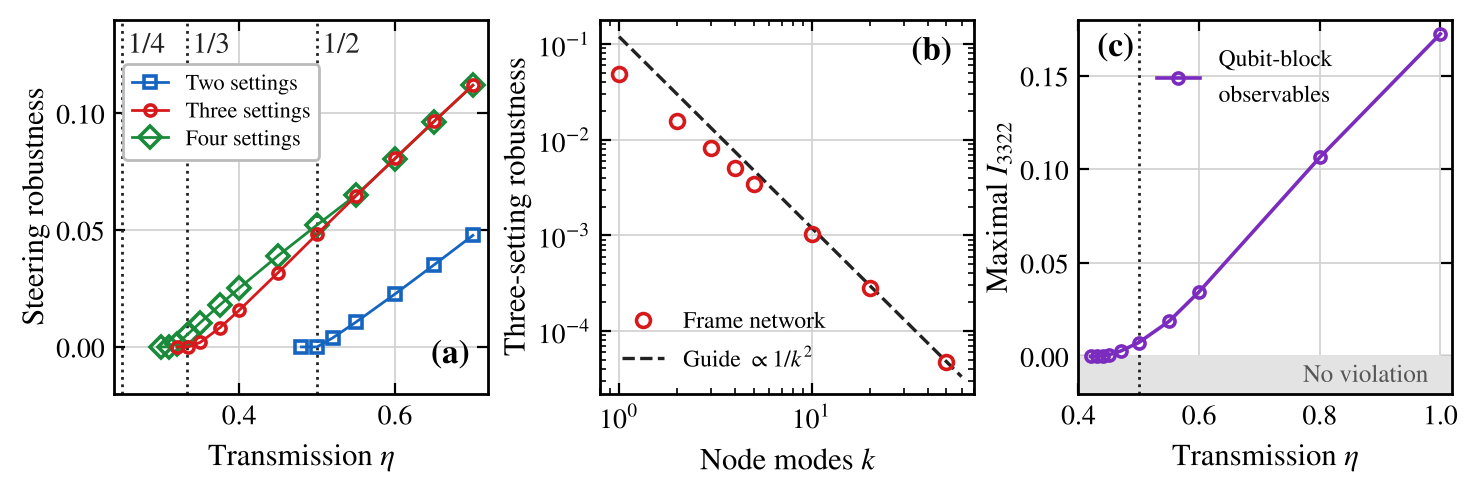

In [23]:
# ============================ Figure 5: three and four settings ============================
# three square panels placed in inches, with gaps just wide enough for the tick and axis labels
W, PW, B, T = 7.2, 1.87, 0.44, 0.06
X0 = [0.50, 0.50 + PW + 0.56, 0.50 + 2*PW + 0.56 + 0.52]          # left edges of the panels
fig = plt.figure(figsize=(W, B + PW + T))
a1, a2, a3 = [fig.add_axes([x/W, B/(B + PW + T), PW/W, PW/(B + PW + T)]) for x in X0]
grid(a1)
for n_, col, mk_, ms_, z_, lab in [('2', BLUE, 's', 4.5, 3, 'Two settings'), ('4', GREEN, 'D', 5.5, 3, 'Four settings'), ('3', RED, 'o', 4.0, 4, 'Three settings')]:
    pp = np.array(sr[n_]); a1.plot(pp[:, 0], pp[:, 1], '-', color=col, lw=1.0, marker=mk_, ms=ms_, mec=col, label=lab, zorder=z_, **OPEN)
h_, l_ = a1.get_legend_handles_labels(); order = [l_.index(x) for x in ['Two settings', 'Three settings', 'Four settings']]
for x, t in [(1 / 4, '1/4'), (1 / 3, '1/3'), (1 / 2, '1/2')]:
    a1.axvline(x, color=DARK, ls=':', lw=1, zorder=2); a1.text(x + 0.007, 0.129, t, fontsize=10.5, color=DARK, va='center')
a1.set_xlim(0.24, 0.72); a1.set_ylim(-0.02, 0.14); a1.set_xlabel(r'Transmission $\eta$'); a1.set_ylabel('Steering robustness', labelpad=2)
lg = a1.legend([h_[i] for i in order], [l_[i] for i in order], loc='upper left', bbox_to_anchor=(0.0, 0.905), ncol=1, frameon=True, framealpha=1, facecolor='white', edgecolor='#bbbbbb', fontsize=8, handlelength=1.6, labelspacing=0.25, borderaxespad=0.4)
lg.set_zorder(10)
plabel(a1, '(a)', 0.95, 0.06, ha='right'); a1.texts[-1].set_va('bottom')
grid(a2)
qq = np.array(net)
a2.loglog(qq[:, 0], qq[:, 2], 'o', ms=5, color=RED, mec=RED, zorder=3, label='Frame network', **OPEN)
kk = np.logspace(0, np.log10(60), 50); a2.loglog(kk, qq[-1, 2] * qq[-1, 0] ** 2 / kk ** 2, '--', color=DARK, lw=1.2, zorder=2, label=r'Guide $\propto 1/k^2$')
a2.set_xlabel(r'Node modes $k$'); a2.set_ylabel('Three-setting robustness', labelpad=2); a2.set_xlim(0.8, 70)
a2.legend(loc='lower left', ncol=1, fontsize=8.5, handlelength=1.8, borderaxespad=0.5); plabel(a2, '(b)', 0.94, 0.96, ha='right')
b = np.array(bell)
grid(a3)
a3.axhspan(-0.02, 0, color=GRAY, zorder=1); a3.text(0.98, -0.017, 'No violation', ha='right', va='bottom', fontsize=9, color='#555555', zorder=2)
a3.plot(b[:, 0], b[:, 1], '-', color=PURPLE, lw=1.3, marker='o', ms=4, mec=PURPLE, zorder=3, label='Qubit-block\nobservables', **OPEN)
a3.axvline(0.5, color=DARK, ls=':', lw=1, zorder=2)
a3.set_xlabel(r'Transmission $\eta$'); a3.set_ylabel(r'Maximal $I_{3322}$', labelpad=2); a3.set_xlim(0.4, 1.02); a3.set_xticks([0.4, 0.6, 0.8, 1.0]); a3.set_ylim(-0.02, 0.18)
a3.legend(loc='upper left', bbox_to_anchor=(0.16, 0.99), ncol=1, fontsize=8.5, handlelength=1.8, borderaxespad=0.4); plabel(a3, '(c)', 0.05, 0.97)
fig.savefig(OUT + 'fig5.pdf'); plt.show()

## 7. Teleportation and entanglement (Sec. 8)

**Theorem 8.** The unit-gain fidelity, maximized over the local symplectic transformations of the protocol class of Sec. 8.1, never exceeds $1/(2-\zeta_j)$. The printed number is the largest value of $F-1/(2-\zeta_j)$ over random states.

In [24]:
def best_fidelity(VA, VAY, VY, k, starts=12):
    W = np.block([[VA, VAY], [VAY.T, VY]]); nA = (2*k)*(2*k+1)//2
    def neg(p):
        SA = sp_from(p[:nA], k); SY = sp_from(p[nA:nA+3], 1)
        L = np.vstack([np.r_[SA[0], SY[0]], np.r_[SA[1], -SY[1]]]); N = L @ W @ L.T
        return -2/np.sqrt(np.linalg.det(2*I2 + N))
    return max(-minimize(neg, rng.normal(size=nA+3)*0.5, method='BFGS').fun for _ in range(starts))
tele = []; viol = -9
for t in range(60 if QUICK else 140):
    k = int(rng.integers(1, 3)); m = int(rng.integers(1, 4)); e = int(rng.integers(0, 3)); n = max(k, m + e)
    V = state(k, rand_symp(n), rng.uniform(0.1, 1.5, size=k)); VA, VAY, VY = blocks(V, k, 0)
    z = share(VA, VAY, VY, k)[0]
    if z < -0.6: continue
    F = best_fidelity(VA, VAY, VY, k, starts=5); tele.append((z, F)); viol = max(viol, F - 1/(2 - z))
print('neighbors tested:', len(tele), '  max (F - 1/(2-zeta)) =', viol)

neighbors tested: 116   max (F - 1/(2-zeta)) = -0.00404955012388275


**Proposition 9 (tightness).** For the tight-frame network, the optimal squeezing $\cosh2r=(1+\eta)/(1-\eta)$ with $\eta=k/(2k-1)$ gives $F=(2k-1)/(3k-2)>2/3$ for every neighbor, Eq. (71).

In [25]:
for k in range(2, 7):
    eta = k/(2*k - 1); v = (1 + eta)/(1 - eta); r = np.arccosh(v)/2; dB = 20*np.log10(np.e)*r
    nmin = v*(1 + eta) - 2*np.sqrt(eta*(v*v - 1)) + 1 - eta; F = 2/(2 + nmin)
    print(f'k={k}: optimal squeezing {dB:.1f} dB, F = {F:.4f} = (2k-1)/(3k-2) = {(2*k - 1)/(3*k - 2):.4f} > 2/3')

k=2: optimal squeezing 10.0 dB, F = 0.7500 = (2k-1)/(3k-2) = 0.7500 > 2/3
k=3: optimal squeezing 9.0 dB, F = 0.7143 = (2k-1)/(3k-2) = 0.7143 > 2/3
k=4: optimal squeezing 8.6 dB, F = 0.7000 = (2k-1)/(3k-2) = 0.7000 > 2/3
k=5: optimal squeezing 8.4 dB, F = 0.6923 = (2k-1)/(3k-2) = 0.6923 > 2/3
k=6: optimal squeezing 8.2 dB, F = 0.6875 = (2k-1)/(3k-2) = 0.6875 > 2/3


### Figure 6: teleportation

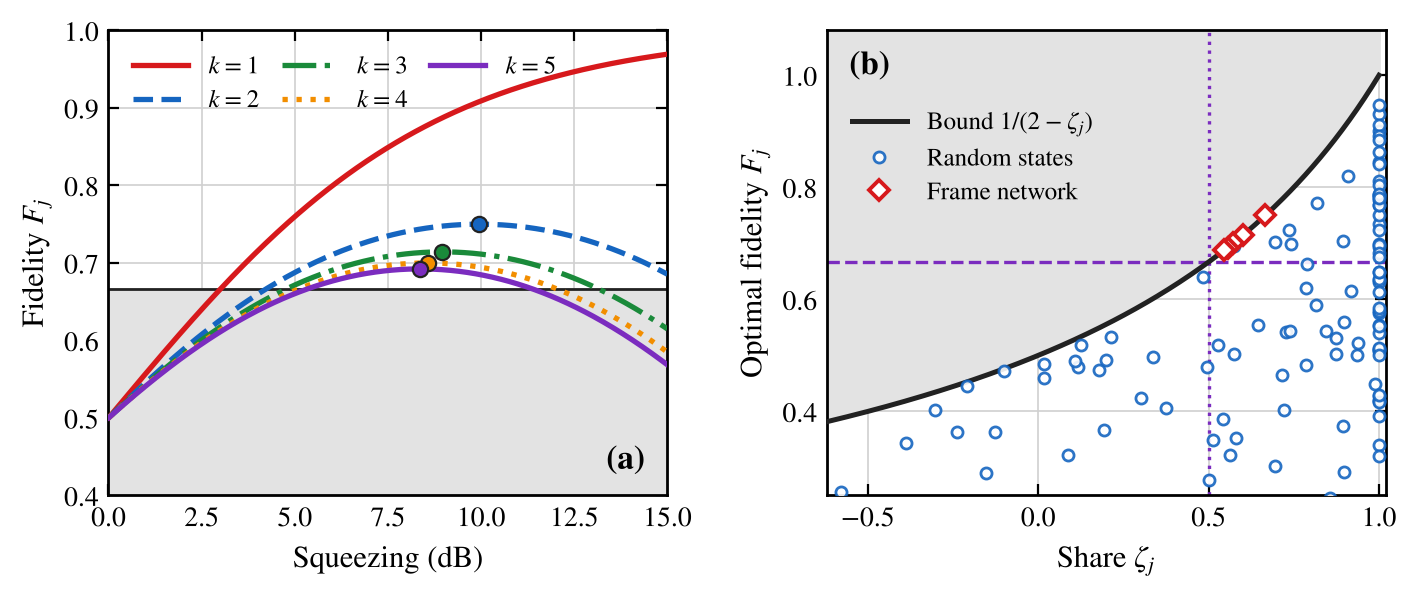

In [26]:
# ============================ Figure 6 (in paper): teleportation ============================
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.1))
grid(a1)
a1.axhspan(0.4, 2 / 3, color=GRAY, zorder=1); a1.axhline(2 / 3, color=DARK, lw=1, zorder=2)
dbs = np.linspace(0.01, 15, 400); r = dbs / (20 * np.log10(np.e)); v = np.cosh(2 * r)
for i, k in enumerate([1, 2, 3, 4, 5]):
    et = k / (2 * k - 1); nn = v * (1 + et) - 2 * np.sqrt(et * (v ** 2 - 1)) + 1 - et; F = 2 / (2 + nn)
    a1.plot(dbs, F, color=COLS[i], ls=['-', '--', '-.', ':', '-'][i], lw=1.9, label='$k=%d$' % k, zorder=3)
    if k > 1:
        vo = (1 + et) / (1 - et); ro = np.arccosh(vo) / 2
        a1.plot(20 * np.log10(np.e) * ro, 1 / (2 - et), 'o', ms=5.5, color=COLS[i], mec=DARK, mew=0.8, zorder=4)
a1.set_xlim(0, 15); a1.set_ylim(0.4, 1.0); a1.set_xlabel('Squeezing (dB)'); a1.set_ylabel(r'Fidelity $F_j$')
a1.legend(loc='upper left', ncol=3, columnspacing=0.9, **LEG); plabel(a1, '(a)', 0.96, 0.04, ha='right'); a1.texts[-1].set_va('bottom')
t = np.array(tele); z = np.linspace(-0.62, 1, 300)
grid(a2)
a2.fill_between(z, 1 / (2 - z), 1.15, color=GRAY, zorder=1)
a2.plot(z, 1 / (2 - z), '-', color=DARK, lw=1.8, label=r'Bound $1/(2-\zeta_j)$', zorder=3)
a2.plot(t[:, 0], t[:, 1], 'o', ms=4, color=BLUE, mec=BLUE, mfc='white', mew=1.0, alpha=0.9, label='Random states', zorder=4)
ks = np.arange(2, 7)
a2.plot(ks / (2 * ks - 1), (2 * ks - 1) / (3 * ks - 2), 'D', ms=5, color=RED, mec=RED, mfc='white', mew=1.4, label='Frame network', zorder=5)
a2.axhline(2 / 3, color=PURPLE, lw=1.2, ls='--', zorder=2); a2.axvline(0.5, color=PURPLE, lw=1.2, ls=':', zorder=2)
a2.set_xlim(-0.62, 1.02); a2.set_ylim(0.25, 1.08); a2.set_xlabel(r'Share $\zeta_j$'); a2.set_ylabel(r'Optimal fidelity $F_j$')
a2.legend(loc='upper left', bbox_to_anchor=(0.0, 0.88), ncol=1, **LEG); plabel(a2, '(b)', 0.04, 0.96)
fig.tight_layout(w_pad=1.6); fig.savefig(OUT + 'fig6.pdf'); plt.show()

### Entanglement reaches every neighbor (Sec. 8.4, Proposition 10)
Logarithmic negativity, Eq. (74), between the node and each of $m$ neighbors when $k$ partner modes with squeezing $r=1$ are split equally, so that every pair is a two-mode squeezed vacuum seen through loss of transmission $k/m$.

In [27]:
def LN(r, eta):
    v = np.cosh(2*r); s = np.sinh(2*r); w = eta*v + 1 - eta; c = np.sqrt(eta)*s
    nu = ((v + w) - np.sqrt((v - w)**2 + 4*c*c))/2; return max(0, -np.log2(nu))
if 'nd' not in globals(): nd = {}
nd['ln'] = {str(k): [(m, LN(1.0, k/m)) for m in range(k, 13)] for k in [1, 2, 3]}
for k in ['1', '2', '3']: print(f'k={k}: E_N for m=k..12:', [round(float(x), 3) for _, x in nd['ln'][k]])

k=1: E_N for m=k..12: [2.885, 1.266, 0.852, 0.648, 0.525, 0.442, 0.382, 0.337, 0.301, 0.272, 0.249, 0.229]
k=2: E_N for m=k..12: [2.885, 1.713, 1.266, 1.016, 0.852, 0.736, 0.648, 0.58, 0.525, 0.48, 0.442]
k=3: E_N for m=k..12: [2.885, 1.96, 1.529, 1.266, 1.086, 0.954, 0.852, 0.771, 0.704, 0.648]


### Figure 7: entanglement and shares under equal splitting

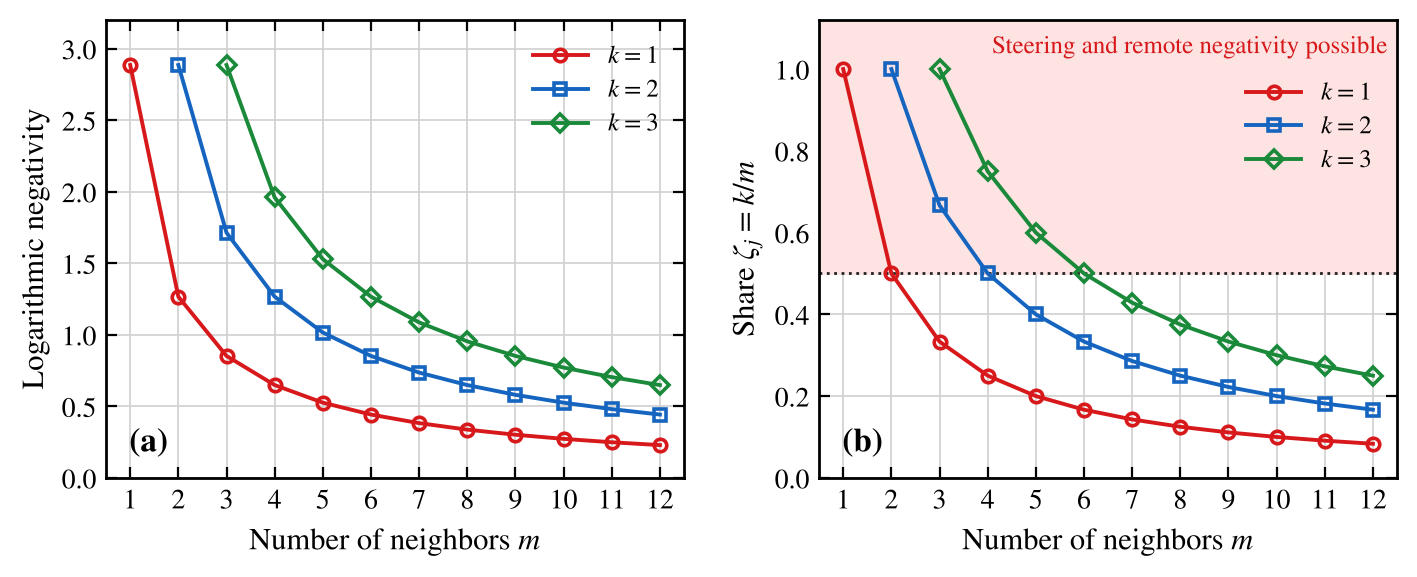

In [28]:
# ============================ Figure 7 (in paper): entanglement and shares under splitting ============================
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.0))
mk = ['o', 's', 'D']
grid(a1)
for i, k in enumerate(['1', '2', '3']):
    p = np.array(nd['ln'][k])
    a1.plot(p[:, 0], p[:, 1], '-', color=COLS[i], marker=mk[i], ms=4.5, mec=COLS[i], lw=1.4, label='$k=%s$' % k, zorder=3, **OPEN)
a1.set_xlabel(r'Number of neighbors $m$'); a1.set_ylabel('Logarithmic negativity'); a1.set_xlim(0.5, 12.5); a1.set_ylim(0, 3.2)
a1.set_xticks(range(1, 13)); a1.legend(loc='upper right', ncol=1, **LEG); plabel(a1, '(a)', 0.04, 0.04); a1.texts[-1].set_va('bottom')
grid(a2)
a2.axhspan(0.5, 1.12, color='#fde3e1', zorder=1)
a2.text(12.3, 1.085, 'Steering and remote negativity possible', ha='right', va='top', fontsize=9, color=RED, zorder=2)
a2.axhline(0.5, color=DARK, lw=1, ls=':', zorder=2)
for i, k in enumerate([1, 2, 3]):
    m = np.arange(k, 13); z = k / m
    a2.plot(m, z, '-', color=COLS[i], lw=1.4, marker=mk[i], ms=4.5, mec=COLS[i], zorder=3, label='$k=%d$' % k, **OPEN)
a2.set_xlabel(r'Number of neighbors $m$'); a2.set_ylabel(r'Share $\zeta_j=k/m$'); a2.set_xlim(0.5, 12.5); a2.set_ylim(0, 1.12)
a2.set_xticks(range(1, 13)); a2.legend(loc='upper right', bbox_to_anchor=(1.0, 0.92), ncol=1, **LEG); plabel(a2, '(b)', 0.04, 0.04); a2.texts[-1].set_va('bottom')
fig.tight_layout(w_pad=1.6); fig.savefig(OUT + 'fig7.pdf'); plt.show()

In [29]:
print('total run time: %.1f min' % ((time.time() - T0)/60))

total run time: 38.7 min
